# Notebook 1. Seoul Bikes – Entrenamiento y persistencia de pipelines

Curso: Machine Learning

Integrantes: Juan Esteban Giraldo Giraldo / Federico Avalos Zuleta

**Propósito:** empaquetar el mismo modelo del cuaderno principal (`EDA_de_Seoul_Bike_Rent_Entrega_v3.ipynb`): entrenar una red MLP de regresión que predice las bicicletas rentadas por hora en Seúl, separar el preprocesamiento del modelamiento y guardar ambos objetos con `joblib`.

Al finalizar, se habrán creado en `artifacts/`:

- `seoul_pipeline_prep.joblib`
- `seoul_pipeline_modelo.joblib`
- `seoul_metadata.json`
- `seoul_predicciones_referencia.csv`

El segundo notebook los recuperará sin volver a entrenar.

**Dataset:** Seoul Bike Sharing Demand (UCI 560), archivo `dataset/SeoulBikeData.csv`.

## 1. Preparar el entorno

Este notebook debe ejecutarse desde el entorno `venv_ml` creado con `uv`. Antes de continuar, verificar que Jupyter esté usando el kernel correcto.

In [3]:
# Carga las librerías del flujo (datos, gráficas, modelamiento, métricas y persistencia) y muestra las versiones del entorno
import json
import platform
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("Python:", platform.python_version())
print("scikit-learn:", sklearn.__version__)

Python: 3.13.3
scikit-learn: 1.9.1


### Configuración

Rutas, semilla, variables y rejilla de hiperparámetros. La carpeta `artifacts/` se ubica en la raíz del proyecto (funciona ejecutando desde `notebooks/` o desde la raíz).

In [4]:
# Define rutas del proyecto, semilla, variables del modelo y rejilla de hiperparámetros a explorar
RAIZ_PROYECTO = Path.cwd()
if RAIZ_PROYECTO.name == "notebooks":
    RAIZ_PROYECTO = RAIZ_PROYECTO.parent

RUTA_DATOS = RAIZ_PROYECTO / "dataset" / "SeoulBikeData.csv"
RUTA_ARTIFACTOS = RAIZ_PROYECTO / "artifacts"
RUTA_PREP = RUTA_ARTIFACTOS / "seoul_pipeline_prep.joblib"
RUTA_MODELO = RUTA_ARTIFACTOS / "seoul_pipeline_modelo.joblib"
RUTA_METADATA = RUTA_ARTIFACTOS / "seoul_metadata.json"
RUTA_REFERENCIA = RUTA_ARTIFACTOS / "seoul_predicciones_referencia.csv"

NOMBRE_MODELO = "seoul_bikes_mlp"
SEMILLA = 42
TEST_SIZE = 0.25

COLUMNAS_NUMERICAS = ["Hour", "Humidity(%)", "Temperature(°C)", "Rainfall(mm)", "Snowfall (cm)"]
COLUMNAS_CATEGORICAS = ["Seasons", "Holiday", "Day of week"]
VARIABLE_SALIDA = "Rented Bike Count"

# Rejilla de hiperparámetros: arquitectura, activación y regularización
REJILLA = {
    "regressor__mlp__hidden_layer_sizes": [(8,), (32,), (64,), (16, 16), (32, 16), (32, 32), (32, 16, 8)],
    "regressor__mlp__activation": ["relu", "identity"],   # identity = activación lineal
    "regressor__mlp__alpha": [1e-4, 1e-2],
}
METRICAS_CV = {"RMSE": "neg_root_mean_squared_error", "R2": "r2"}

## 2. Cargar y explorar los datos

Cada fila es una hora de un día, con las condiciones climáticas y de calendario. La variable objetivo es `Rented Bike Count`.

In [5]:
# Lee el CSV original y muestra cuántas horas corresponden a días con y sin servicio
datos_crudos = pd.read_csv(RUTA_DATOS, encoding="latin-1")

print("Dimensiones:", datos_crudos.shape)
display(datos_crudos.head())
display(datos_crudos["Functioning Day"].value_counts())

Dimensiones: (8760, 14)


,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


Functioning Day
Yes    8465
No      295
Name: count, dtype: int64

,count,mean,std,min,25%,50%,75%,max,nulos,ceros
Rented Bike Count,8760.0,704.602055,644.997468,0.0,191.00,504.50,1065.25,3556.00,0,295
Hour,8760.0,11.500000,6.922582,0.0,5.75,11.50,17.25,23.00,0,365
Temperature(°C),8760.0,12.882922,11.944825,-17.8,3.50,13.70,22.50,39.40,0,21
Humidity(%),8760.0,58.226256,20.362413,0.0,42.00,57.00,74.00,98.00,0,17
Wind speed (m/s),8760.0,1.724909,1.036300,0.0,0.90,1.50,2.30,7.40,0,74
Visibility (10m),8760.0,1436.825799,608.298712,27.0,940.00,1698.00,2000.00,2000.00,0,0
Dew point temperature(°C),8760.0,4.073813,13.060369,-30.6,-4.70,5.10,14.80,27.20,0,60
Solar Radiation (MJ/m2),8760.0,0.569111,0.868746,0.0,0.00,0.01,0.93,3.52,0,4300
Rainfall(mm),8760.0,0.148687,1.128193,0.0,0.00,0.00,0.00,35.00,0,8232
Snowfall (cm),8760.0,0.075068,0.436746,0.0,0.00,0.00,0.00,8.80,0,8317


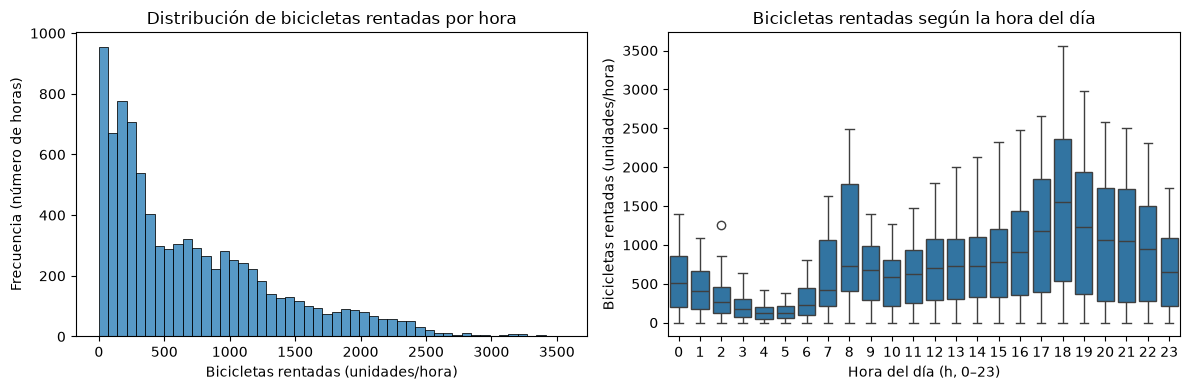

In [6]:
# Resume cada variable (incluye nulos y ceros) y grafica la distribución de la salida y su variación por hora
resumen = datos_crudos.describe().T
resumen["nulos"] = datos_crudos.isna().sum()
resumen["ceros"] = (datos_crudos.select_dtypes("number") == 0).sum()
display(resumen)

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(datos_crudos[VARIABLE_SALIDA], bins=50, ax=ejes[0])
ejes[0].set_title("Distribución de bicicletas rentadas por hora")
ejes[0].set_xlabel("Bicicletas rentadas (unidades/hora)")
ejes[0].set_ylabel("Frecuencia (número de horas)")
sns.boxplot(data=datos_crudos, x="Hour", y=VARIABLE_SALIDA, ax=ejes[1])
ejes[1].set_title("Bicicletas rentadas según la hora del día")
ejes[1].set_xlabel("Hora del día (h, 0–23)")
ejes[1].set_ylabel("Bicicletas rentadas (unidades/hora)")
plt.tight_layout()
plt.show()

**Análisis.** 

Al analizar los datos vemos que la demanda es muy desigual, la mayoría de las horas tienen menos de ~1.000 rentas y pocas superan las 3.000.Para que la red neuronal no se descontrole con saltos tan grandes, escalamos los valores antes de entrenar y evaluamos el modelo con dos métricas: una para el error promedio (MAE) y otra que castiga más los fallos en horas pico (RMSE).Además, el gráfico por horas confirma que la rutina diaria es clave, con un bajón total de madrugada y dos grandes picos a las 8 de la mañana y a las 6 de la tarde. Por último, aunque no hay datos nulos, detectamos registros falsos que debemos limpiar: mediciones imposibles de 0 % de humedad y 295 horas con cero alquileres que corresponden a días sin servicio."

## 3. Limpieza y creación de columnas

Esta etapa ocurre **antes** de los pipelines y debe repetirse igual en inferencia:

1. Se conservan solo los días en funcionamiento (`Functioning Day == "Yes"`); los demás tienen 0 rentas por definición.
2. Se crea `Day of week` a partir de `Date`.
3. La humedad en 0 % (físicamente imposible) se reemplaza por interpolación lineal dentro de cada hora.

In [7]:
# Aplica la limpieza previa (días con servicio, día de la semana, humedad) que también se repetirá en inferencia
def limpiar_datos(df):
    """Filtra días en funcionamiento, crea 'Day of week' e imputa la humedad en 0 %."""
    df = df[df["Functioning Day"] == "Yes"].copy()

    df["Date"] = pd.to_datetime(df["Date"], format="%d/%m/%Y")
    df["Day of week"] = df["Date"].dt.day_name().astype(str)

    # Humedad 0 % (imposible) -> NaN e interpolación lineal por hora
    df["Humidity(%)"] = df["Humidity(%)"].replace(0, np.nan)
    df["Humidity(%)"] = df.groupby("Hour")["Humidity(%)"].transform(
        lambda x: x.interpolate(method="linear")
    )
    return df.reset_index(drop=True)


datos = limpiar_datos(datos_crudos)
print("Dimensiones después de limpiar:", datos.shape)
print("Humedad en 0 % restante:", (datos["Humidity(%)"] == 0).sum())

Dimensiones después de limpiar: (8465, 15)
Humedad en 0 % restante: 0


## 4. Separar entrenamiento y prueba

La separación se realiza antes de ajustar cualquier transformación. El preprocesamiento se ajustará exclusivamente con `X_train`; después se aplicará a entrenamiento y prueba.

### Variables de entrada y salida del modelo predictivo

| Rol | Variable | Tipo |
|---|---|---|
| Entrada | `Hour` | Numérica discreta (0–23 h) |
| Entrada | `Humidity(%)` | Numérica continua (%) |
| Entrada | `Temperature(°C)` | Numérica continua (°C) |
| Entrada | `Rainfall(mm)` | Numérica continua (mm) |
| Entrada | `Snowfall (cm)` | Numérica continua (cm) |
| Entrada | `Seasons` | Categórica nominal (4) |
| Entrada | `Holiday` | Categórica binaria |
| Entrada | `Day of week` | Categórica nominal (7), creada desde `Date` |
| **Salida** | `Rented Bike Count` | Numérica discreta: bicicletas rentadas por hora |

In [8]:
# Separa variables de entrada y salida y reserva el 25 % de los datos como conjunto de prueba
X = datos[COLUMNAS_NUMERICAS + COLUMNAS_CATEGORICAS]
y = datos[VARIABLE_SALIDA]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=SEMILLA,
)

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)

Entrenamiento: (6348, 8)
Prueba: (2117, 8)


## 5. Construir y ajustar el pipeline de preprocesamiento

`pipeline_prep` recibe las variables crudas y aplica un `ColumnTransformer`:

1. Las variables numéricas pasan sin cambios (`passthrough`).
2. `OneHotEncoder` convierte `Seasons`, `Holiday` y `Day of week` en variables dummy (`handle_unknown="ignore"` evita errores con categorías nuevas).

El resultado son las mismas 18 columnas, en el mismo orden, que usa el cuaderno principal. El escalado queda dentro del pipeline del modelo para que, igual que en el cuaderno principal, se ajuste de nuevo en cada partición de la validación cruzada. El ajuste se realiza exclusivamente con `X_train`.

In [9]:
# Construye el pipeline de preprocesamiento y lo ajusta solo con entrenamiento para evitar fuga de información
pipeline_prep = Pipeline(steps=[
    ("columnas", ColumnTransformer([
        ("num", "passthrough", COLUMNAS_NUMERICAS),
        ("cat", OneHotEncoder(sparse_output=False, handle_unknown="ignore"), COLUMNAS_CATEGORICAS),
    ])),
])

# Ajustar exclusivamente con entrenamiento.
X_train_prep = pipeline_prep.fit_transform(X_train)
X_test_prep = pipeline_prep.transform(X_test)

print("Dimensiones preprocesadas - train:", X_train_prep.shape)
print("Dimensiones preprocesadas - test:", X_test_prep.shape)

Dimensiones preprocesadas - train: (6348, 18)
Dimensiones preprocesadas - test: (2117, 18)


## 6. Construir y entrenar el pipeline de modelamiento

`pipeline_modelo` recibe los datos ya transformados por `pipeline_prep` y es el mismo modelo del cuaderno principal:

- `TransformedTargetRegressor` que estandariza la salida durante el entrenamiento y la devuelve a su escala original al predecir.
- Dentro de él, un `Pipeline` con `StandardScaler` (escala las 18 entradas) y `MLPRegressor` (solver `adam`).

Los hiperparámetros se eligen con `GridSearchCV` de 5 particiones sobre el conjunto de entrenamiento, quedándose con el menor RMSE.

In [10]:
# Busca la mejor arquitectura de la MLP con validación cruzada de 5 particiones y predice el conjunto de prueba
pipeline_base = TransformedTargetRegressor(
    regressor=Pipeline([
        ("escalador", StandardScaler()),
        ("mlp", MLPRegressor(solver="adam", max_iter=2000, random_state=SEMILLA)),
    ]),
    transformer=StandardScaler(),
)

busqueda = GridSearchCV(
    pipeline_base,
    REJILLA,
    cv=5,
    scoring=METRICAS_CV,
    n_jobs=-1,
    refit="RMSE",
)
busqueda.fit(X_train_prep, y_train)

pipeline_modelo = busqueda.best_estimator_
y_pred = pipeline_modelo.predict(X_test_prep)

print("Mejores hiperparámetros:", busqueda.best_params_)
print(f"RMSE medio en validación cruzada: {-busqueda.best_score_:.3f}")
print(f"R2 medio en validación cruzada: {busqueda.cv_results_['mean_test_R2'][busqueda.best_index_]:.3f}")

Mejores hiperparámetros: {'regressor__mlp__activation': 'relu', 'regressor__mlp__alpha': 0.01, 'regressor__mlp__hidden_layer_sizes': (32, 16)}
RMSE medio en validación cruzada: 232.741
R2 medio en validación cruzada: 0.870


## 7. Evaluar el modelo

Se comparan las métricas de prueba contra una línea base que siempre predice la media de entrenamiento.

{
  "cv_RMSE": 232.74110002079433,
  "cv_R2": 0.8699716626040154,
  "test_RMSE": 227.39175546031132,
  "test_MAE": 147.75727798043224,
  "test_R2": 0.8690751571098208,
  "baseline_RMSE_media": 628.6132582235725
}


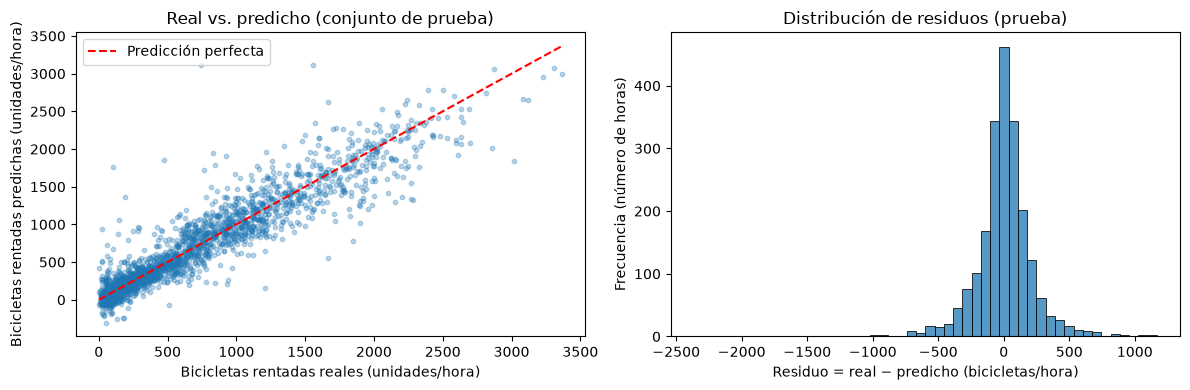

In [11]:
# Calcula las métricas de prueba, las compara con la línea base y grafica real vs. predicho y los residuos
metricas = {
    "cv_RMSE": float(-busqueda.best_score_),
    "cv_R2": float(busqueda.cv_results_["mean_test_R2"][busqueda.best_index_]),
    "test_RMSE": float(np.sqrt(mean_squared_error(y_test, y_pred))),
    "test_MAE": float(mean_absolute_error(y_test, y_pred)),
    "test_R2": float(r2_score(y_test, y_pred)),
    "baseline_RMSE_media": float(np.sqrt(mean_squared_error(y_test, np.full(len(y_test), y_train.mean())))),
}
print(json.dumps(metricas, indent=2))

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].scatter(y_test, y_pred, alpha=0.3, s=10)
limite = max(y_test.max(), y_pred.max())
ejes[0].plot([0, limite], [0, limite], "r--", label="Predicción perfecta")
ejes[0].set_xlabel("Bicicletas rentadas reales (unidades/hora)")
ejes[0].set_ylabel("Bicicletas rentadas predichas (unidades/hora)")
ejes[0].set_title("Real vs. predicho (conjunto de prueba)")
ejes[0].legend()
sns.histplot(y_test - y_pred, bins=50, ax=ejes[1])
ejes[1].set_title("Distribución de residuos (prueba)")
ejes[1].set_xlabel("Residuo = real − predicho (bicicletas/hora)")
ejes[1].set_ylabel("Frecuencia (número de horas)")
plt.tight_layout()
plt.show()

**Análisis.** 

Las métricas son las mismas del cuaderno principal, el modelo tiene un desempeño muy sólido donde explica el 87 % del comportamiento de la demanda y reduce casi a una tercera parte el error que tendríamos usando solo el promedio histórico. Además, como el error en la prueba final es casi idéntico al de la validación, confirmamos que no hay sobreajuste. Al observar los gráficos, las predicciones siguen muy bien la diagonal ideal, aunque en horas de mucha demanda (más de 2.000 bicicletas) tiende a quedarse un poco corto, y en momentos de muy baja actividad lanza algunos valores negativos que ajustamos a cero. Por último, el gráfico de la derecha muestra que los fallos se reparten de forma pareja a ambos lados del cero, lo que indica que el modelo no tiende ni a exagerar ni a quedarse corto.



## 8. Persistir los dos pipelines

`joblib.dump` guarda el estado ajustado de cada objeto:

- `pipeline_prep` conserva medias, desviaciones y categorías aprendidas.
- `pipeline_modelo` conserva los pesos de la red y el escalador de la salida.

Además se guardan la **metadata** (variables, versiones, hiperparámetros y métricas) y las **predicciones de referencia** del conjunto de prueba, para que el Notebook 2 pueda comprobar la integridad en otra sesión.

**Advertencia de seguridad:** los archivos serializados con joblib/pickle pueden ejecutar código al cargarse. Carga únicamente artefactos de procedencia confiable.

In [12]:
# Guarda los dos pipelines, la metadata del entorno y las predicciones de referencia en artifacts/
mlp = pipeline_modelo.regressor_.named_steps["mlp"]
onehot = pipeline_prep.named_steps["columnas"].named_transformers_["cat"]

metadata = {
    "nombre_modelo": NOMBRE_MODELO,
    "descripcion": "Dos pipelines: pipeline_prep (OneHotEncoder) y pipeline_modelo "
                   "(StandardScaler + MLPRegressor con salida estandarizada) para predecir bicicletas rentadas por hora en Seúl.",
    "archivos": {
        "pipeline_prep": RUTA_PREP.name,
        "pipeline_modelo": RUTA_MODELO.name,
        "predicciones_referencia": RUTA_REFERENCIA.name,
    },
    "uso": "y = pipeline_modelo.predict(pipeline_prep.transform(X[variables_entrada]))",
    "fecha_entrenamiento": datetime.now().isoformat(timespec="seconds"),
    "autores": ["Juan Esteban Giraldo Giraldo", "Federico Avalos Zuleta"],
    "dataset": "Seoul Bike Sharing Demand (UCI 560)",
    "variable_salida": VARIABLE_SALIDA,
    "variables_entrada": COLUMNAS_NUMERICAS + COLUMNAS_CATEGORICAS,
    "variables_numericas": COLUMNAS_NUMERICAS,
    "variables_categoricas": COLUMNAS_CATEGORICAS,
    "categorias_one_hot": {col: [str(v) for v in cats]
                           for col, cats in zip(COLUMNAS_CATEGORICAS, onehot.categories_)},
    "preprocesamiento_previo": [
        "Filtrar Functioning Day == Yes",
        "Day of week creada a partir de Date (nombre del día en inglés)",
        "Humedad 0 % reemplazada por interpolación lineal por hora",
    ],
    "pipeline_prep": [
        "Variables numéricas sin cambios (passthrough)",
        "OneHotEncoder de variables categóricas",
    ],
    "pipeline_modelo": [
        "StandardScaler de las 18 entradas",
        "MLPRegressor",
        "StandardScaler de la salida (TransformedTargetRegressor)",
    ],
    "hiperparametros_busqueda": {k: [str(v) for v in vals] for k, vals in REJILLA.items()},
    "mejores_hiperparametros": {k: (str(v) if isinstance(v, tuple) else v)
                                for k, v in busqueda.best_params_.items()},
    "arquitectura": {
        "capas_ocultas": list(mlp.hidden_layer_sizes),
        "activacion": mlp.activation,
        "alpha": mlp.alpha,
        "solver": mlp.solver,
        "iteraciones": int(mlp.n_iter_),
    },
    "division_datos": {
        "test_size": TEST_SIZE,
        "random_state": SEMILLA,
        "n_entrenamiento": int(len(X_train)),
        "n_prueba": int(len(X_test)),
    },
    "metricas": metricas,
    "versiones": {
        "python": platform.python_version(),
        "scikit-learn": sklearn.__version__,
        "joblib": joblib.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__,
    },
}

RUTA_ARTIFACTOS.mkdir(parents=True, exist_ok=True)

joblib.dump(pipeline_prep, RUTA_PREP, compress=3)
joblib.dump(pipeline_modelo, RUTA_MODELO, compress=3)
with open(RUTA_METADATA, "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

# Predicciones de referencia: índice de prueba, valor real y predicho
pd.DataFrame({"real": y_test.to_numpy(), "predicho": y_pred}, index=X_test.index).to_csv(
    RUTA_REFERENCIA, index_label="indice"
)

for ruta in (RUTA_PREP, RUTA_MODELO, RUTA_METADATA, RUTA_REFERENCIA):
    print("Guardado:", ruta.resolve())

Guardado: C:\Users\Usuario\Pictures\Entrega_final_Seoul\LabUV\artifacts\seoul_pipeline_prep.joblib
Guardado: C:\Users\Usuario\Pictures\Entrega_final_Seoul\LabUV\artifacts\seoul_pipeline_modelo.joblib
Guardado: C:\Users\Usuario\Pictures\Entrega_final_Seoul\LabUV\artifacts\seoul_metadata.json
Guardado: C:\Users\Usuario\Pictures\Entrega_final_Seoul\LabUV\artifacts\seoul_predicciones_referencia.csv


## 9. Verificación de integridad por reconstrucción

Se cargan los artefactos recién guardados y se comparan las predicciones con las obtenidas antes de guardar. Como es una regresión (valores continuos) se usa `np.allclose`.

In [13]:
# Recarga los artefactos en variables nuevas y comprueba que producen exactamente las mismas predicciones
prep_cargado = joblib.load(RUTA_PREP)
modelo_cargado = joblib.load(RUTA_MODELO)

X_test_prep_cargado = prep_cargado.transform(X_test)
y_pred_cargado = modelo_cargado.predict(X_test_prep_cargado)

assert np.allclose(y_pred, y_pred_cargado), (
    "Las predicciones cambiaron después de guardar y cargar los pipelines."
)

print("Verificación exitosa: las predicciones son idénticas.")

Verificación exitosa: las predicciones son idénticas.


## 10. Actividad de análisis

Responde en una celda Markdown:

1. ¿Qué parámetros aprendidos conserva el pipeline de preprocesamiento?
2. ¿Por qué `fit_transform` se aplica a `X_train`, pero solo `transform` a `X_test`?
3. ¿Qué problema ocurriría si se ajustara el escalador o el one-hot con todos los datos antes de dividir?
4. ¿Qué ventajas y limitaciones tiene guardar preprocesamiento y modelo como dos artefactos independientes?
5. ¿Qué información del entorno debería acompañar a los archivos `.joblib` para facilitar su recuperación?

**Respuestas**

1. El pipeline de preprocesamiento guarda la lista de categorías que vio durante el entrenamiento: las cuatro estaciones del año, si el día es festivo o no, y los siete días de la semana. También en qué orden va cada columna dummy, como una libreta que dice "la columna 1 es invierno, la columna 2 es primavera", y así sucesivamente. Las medias y desviaciones del escalado no están aquí, sino dentro del pipeline del modelo, junto con los pesos de la red neuronal.

2. `fit_transform` aprende las reglas del preprocesamiento con los datos y después las aplica. Se usa en `X_train` porque es el conjunto con el que se entrena el modelo. `transform` solo aplica las reglas que ya se aprendieron, sin cambiarlas, y se usa en `X_test`. Los datos de prueba deben ser datos que el modelo no conoce. Si el pipeline aprendiera también de ellos, la evaluación no sería confiable. Con transform, los datos de prueba se procesan igual que los de entrenamiento, que es lo que pasará con datos nuevos en la vida real.

3. Ocurriría una fuga de información (data leakage). Las medias, desviaciones y categorías se calcularían usando también los datos de prueba, que después se usan para evaluar el modelo. Es como estudiar con las respuestas del examen, las métricas saldrían mejores de lo que realmente son, y el modelo rendiría peor cuando recibiera datos realmente nuevos.

4. La principal ventaja es la flexibilidad, se puede cambiar o reentrenar el modelo sin tocar el preprocesamiento, y se puede revisar cada etapa por separado, lo que facilita encontrar errores. La limitación es que ambos archivos deben mantenerse siempre juntos y con la misma versión. Si se combina un preprocesamiento de una versión con un modelo de otra, las predicciones saldrán incorrectas y no aparecerá ningún mensaje de error. Usar un único Pipeline evita ese riesgo, aunque da menos flexibilidad.

5. Versiones de Python, scikit-learn, NumPy, pandas y joblib; el archivo `requirements-lock.txt`; fecha de entrenamiento; variables de entrada (nombres y orden) y de salida; categorías esperadas; pasos de limpieza previa; hiperparámetros; semilla y partición; y métricas obtenidas. Todo esto se guarda en `seoul_metadata.json`.

## 11. Archivos generados

- `artifacts/seoul_pipeline_prep.joblib`
- `artifacts/seoul_pipeline_modelo.joblib`
- `artifacts/seoul_metadata.json`
- `artifacts/seoul_predicciones_referencia.csv`

En el Notebook 2 se reconstruirá la inferencia utilizando estos archivos, sin ejecutar `fit` ni `fit_transform`.